In [60]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import matplotlib.dates as mdates 

import datetime

plt.style.use("fivethirtyeight")

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

# Don't optimize one plant for maximum yield. Optimize the collection for minimum days of failure.

In [61]:

DB_FILE_PATH = "../db/harvest_main_log_df.csv"

In [62]:
main_df = pd.read_csv(DB_FILE_PATH)

In [63]:
main_df.columns

Index(['Date', 'Total', 'Hibiscus_F', 'Kolkata_Pan_L', 'Mogai_Pan_L',
       'Tulsi_Rama_L', 'Aloe_Vera_L', 'Tulsi_Sabja_L', 'Parijatak_L',
       'Lemon_Grass_L', 'Tulsi_Kapoor_L', 'Tulsi_Krishna_L', 'Pudina_L',
       'Brahmi_L', 'Nirgundi_L', 'Pippali_L', 'Adulsa_L', 'Mogra_F',
       'Tulsi_Sabja_F', 'Neem_L', 'Tulsi_sabja_L', 'Rose_F', 'Fertiliser',
       'Double_Tagar_F', 'Curry_L', 'Tulsi_Krishna_F', 'Jui_L',
       'Sita_Ashoka_L', 'Hibiscus_L'],
      dtype='str')

In [64]:
total_col_name = "Total"
date_col_name = "Date"

In [65]:
main_df.Total = 0 
float_col_names = [col for col in main_df.columns if col not in ["Fertilisers", "Date"]]
print(float_col_names)
main_df[float_col_names] = main_df[float_col_names].apply(pd.to_numeric, errors = 'coerce')
main_df.Total = main_df[float_col_names].sum(axis= 1)

['Total', 'Hibiscus_F', 'Kolkata_Pan_L', 'Mogai_Pan_L', 'Tulsi_Rama_L', 'Aloe_Vera_L', 'Tulsi_Sabja_L', 'Parijatak_L', 'Lemon_Grass_L', 'Tulsi_Kapoor_L', 'Tulsi_Krishna_L', 'Pudina_L', 'Brahmi_L', 'Nirgundi_L', 'Pippali_L', 'Adulsa_L', 'Mogra_F', 'Tulsi_Sabja_F', 'Neem_L', 'Tulsi_sabja_L', 'Rose_F', 'Fertiliser', 'Double_Tagar_F', 'Curry_L', 'Tulsi_Krishna_F', 'Jui_L', 'Sita_Ashoka_L', 'Hibiscus_L']


In [66]:
def plot_harvest(colname, total):
    try :  
        curr_df = main_df.copy() 
        # curr_df = curr_main_df[colname]

        _, ax = plt.subplots(figsize = (20, 10))
        curr_df.Date = pd.to_datetime(curr_df.Date)
        plt.plot(curr_df.Date, curr_df[colname], color='#666', linestyle= "-", linewidth=2, label='Trend')

        if colname != "Total" and total : 
            plt.plot(curr_df.Date, curr_df["Total"], color = '#888', linestyle = 'dashed', linewidth = 1, )

        # 2. The Dots (shows exact daily counts)
        processed_df = curr_df[curr_df[colname] > 0]
        plt.scatter(processed_df.Date, processed_df[colname], color='#333', zorder=5, label='Daily Count')

            # Calculates a 14-day rolling average
        # 'min_periods=1' ensures it still draws a line even if a few days are missing
        processed_df = curr_df.copy() 
        processed_df['Rolling_Avg'] = processed_df[colname].rolling(window=7, min_periods=1, center=True).mean()

        # Plot line
        plt.plot(processed_df['Date'], processed_df['Rolling_Avg'], color='darkcyan', linewidth=2)

        ax = plt.gca() # Get current axis

        # Set ticks to happen at the start of every Month
        ax.xaxis.set_major_locator(mdates.MonthLocator())

        # Format the label to show short Month name and Year (e.g., "Jun 2026")
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
        # plt.gcf().autofmt_xdate()

        daily_avg = round(curr_df[colname].mean(), 2)
        daily_perc_usage = round(len(curr_df[curr_df[colname] > 0 ]) * 100 / len(curr_df), 2) 
        total_harvest = curr_df[colname].sum(axis = 0)

        plt.title(f'{colname} | Total : {total_harvest} | Avg : {daily_avg} | Daily_Perc_Usage : {daily_perc_usage} %', fontsize=30, fontweight='bold', color = "#444")
        plt.xlabel('Month')
        plt.ylabel(colname)
        plt.grid(True, linestyle='--', alpha=0.5)

        plt.show() 
    except KeyError as k:
        plt.close("all")

        print(k)
        print(main_df.columns)
    except ValueError as v: 
        plt.close("all")
        print(v)
    except Exception as e: 
        plt.close("all")
        print(e)



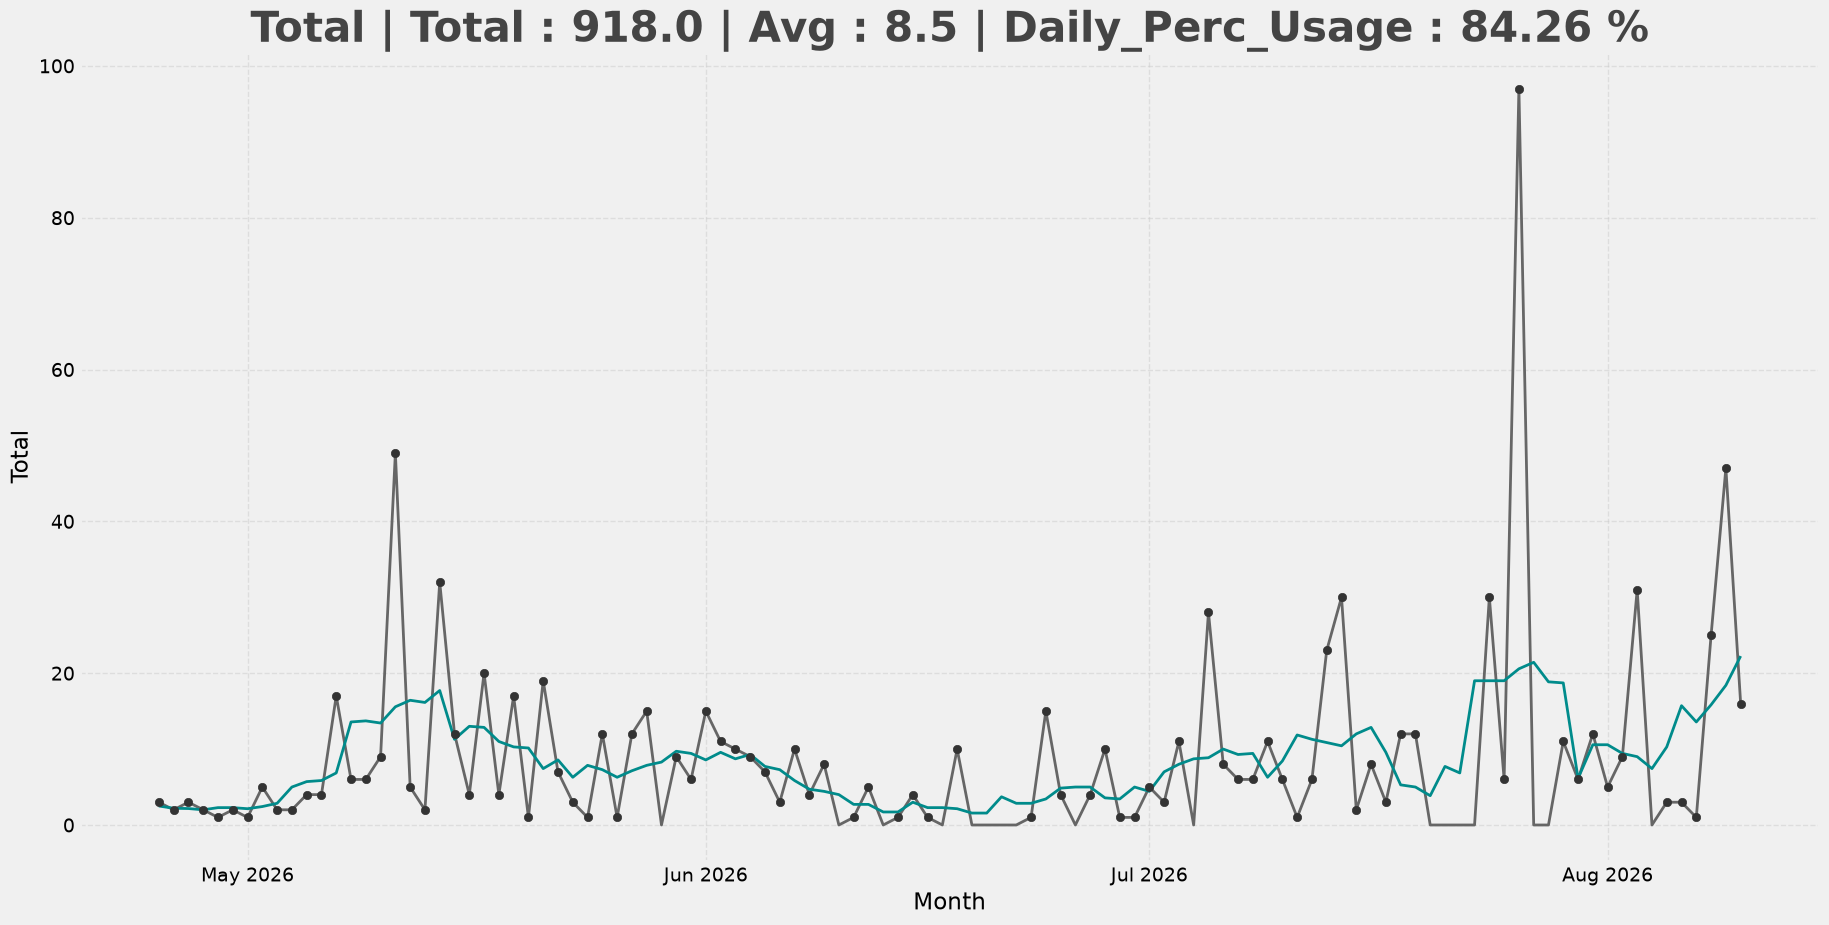

In [74]:
colname = "Total"
# total = False 
fertiliser_info = False 
plot_harvest(colname, total = False ) 

# Plot by harvest Categories 

In [68]:
def plot_by_Cat(cat, show_total, show_cat, show_sub_cat, n_min = 5): 
    # cat = "Tulsi_Vrundavan"
    # show_total = True 
    try:
        main_df.Date = pd.to_datetime(main_df.Date)

        filtered_col = []

        if cat == "all": 
            for c in harvest_category_map: 
                for col in harvest_category_map[c]: 
                    if col in main_df.columns and col not in filtered_col: 
                        filtered_col.append(col)

            
            # print(filtered_col)
        else: 
            for col in harvest_category_map[cat]: 
                if col in main_df.columns:  filtered_col.append(col)

        cat_df = main_df[filtered_col]
        cat_df["Total_x"] = cat_df.sum(axis = 1)
        
        _, ax = plt.subplots(figsize = (20, 10))
        if show_cat: 
            plt.plot(main_df.Date, cat_df["Total_x"], label = cat, linestyle ="dashed", color = "#1e552f", linewidth = 1.8 )
        if show_total :
            plt.plot(main_df.Date, main_df.Total, linestyle = "dashed", color = "#333", label = "Total")

        if show_sub_cat: 
            for col in filtered_col:
                plt.plot(main_df.Date, main_df[col], label = col, alpha = 0.6)

        ax = plt.gca() # Get current axis
        
        # Set ticks to happen at the start of every Month
        ax.xaxis.set_major_locator(mdates.MonthLocator())

        # Format the label to show short Month name and Year (e.g., "Jun 2026")
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
        # plt.gcf().autofmt_xdate()

        _all_sum = cat_df["Total_x"].sum(axis = 0)
        _all_avg = round(_all_sum/ cat_df.shape[0], 2) 
        _daily_perc_usage = round(len(cat_df[cat_df["Total_x"] > 0]) * 100 / len(cat_df), 2) 
        _n_of_zero_days = len(cat_df[cat_df["Total_x"] == 0])
        _n_days = len(cat_df)
        _n_used_days = _n_days - _n_of_zero_days
        n_min_x = round(len(cat_df[cat_df["Total_x"] >= n_min]))
        n_min_x_perc = round((n_min_x * 100)/ _n_days, 2)
        plt.title(f"{cat} : {_all_sum} | Avg : {_all_avg} | n_Days : {_n_days} | Daily : {_daily_perc_usage} % ({_n_used_days})| N_min_{n_min} : {n_min_x} ({n_min_x_perc} %)| NoOf_0 : ({_n_of_zero_days})", fontsize = 20, fontweight = "bold")


        plt.legend(loc = 'upper left')
        plt.xlabel("Month")
        plt.ylabel(cat)
        plt.show()
    except Exception as e: print(e)

In [69]:
main_df.columns 

Index(['Date', 'Total', 'Hibiscus_F', 'Kolkata_Pan_L', 'Mogai_Pan_L',
       'Tulsi_Rama_L', 'Aloe_Vera_L', 'Tulsi_Sabja_L', 'Parijatak_L',
       'Lemon_Grass_L', 'Tulsi_Kapoor_L', 'Tulsi_Krishna_L', 'Pudina_L',
       'Brahmi_L', 'Nirgundi_L', 'Pippali_L', 'Adulsa_L', 'Mogra_F',
       'Tulsi_Sabja_F', 'Neem_L', 'Tulsi_sabja_L', 'Rose_F', 'Fertiliser',
       'Double_Tagar_F', 'Curry_L', 'Tulsi_Krishna_F', 'Jui_L',
       'Sita_Ashoka_L', 'Hibiscus_L'],
      dtype='str')

In [70]:
harvest_category_map = {
    "all" : [],
    "all_medicine" : [],
    "all_flowering" : [], 
    "all_pooja_offerings": [],
    "Tulsi_Vrundavan" : ["Tulsi_Krishna_L", "Tulsi_Rama_L", "Tulsi_Sabja_L", "Tulsi_Sabja_F", "Tulsi_Kapoor_L"],
    "Jasmine" : ["Mogra_F", "Jai_F", "Jui_F", "Kunda_F"],
    "Daily_Pooja_Flowers" : ["Hibiscus_F", "Gokarna_F", "Double_Tagar_F"], 
    "Daily_Pooja_Leaves" : ["Tulsi_Krishna_L", "Tulsi_Rama_L", "Tulsi_Sabja_L", "Tulsi_Sabja_F", "Tulsi_Kapoor_L", "Bael_L"],
    "Fragrance_Flower" : ["Double_Tagar_F", "Sonchafa_F", "Bakul_F", "Mogra_F", "Jai_F", "Jui_F", "Parijatak_F", "Tulsi_Sabja_F", "Gandharaja_F", "Rose_F"],
    "Shiva_Pooja" : ["Rui_L", "Rui_F", "Bael_L", "Dhatura_F", "Dhatura_F2"],
    "Satvic_Flowers" : ["Mogra_F", "Jai_F", "Jui_F", "Kunda_F", "Gokarna_F", "Double_Tagar_F", "Bakul_F", "Parijatak_F", "Gandharaja_F", "Rui_F", "Dhatura_F"],
    "Tea" : ["Jui_L", "Lemon_Grass_L"],
}

def _upd_all(): 

    for col in main_df.columns:
        if col != total_col_name and col != date_col_name: harvest_category_map['all'].append(col) 

def _upd_all_flowers(): 
    for col in main_df.columns: 
        if col[-1] == "F" and col != date_col_name and col != total_col_name: harvest_category_map["all_flowering"].append(col)

def _upd_all_medicine():

    subtract_cols = [total_col_name, date_col_name]
    subtract_cols += harvest_category_map["all_flowering"]
    subtract_cols = set(subtract_cols)

    for col in main_df.columns: 
        if col not in subtract_cols: harvest_category_map["all_medicine"].append(col)

def _upd_all_pooja_offerings(): 
    all_pooja_offerings = set() 
    for col in harvest_category_map["all_flowering"]: 
        all_pooja_offerings.add(col)
    for col in harvest_category_map["Tulsi_Vrundavan"]: 
        all_pooja_offerings.add(col)
    for col in harvest_category_map["Shiva_Pooja"]: 
        all_pooja_offerings.add(col)
    
    harvest_category_map["all_pooja_offerings"] = list(all_pooja_offerings)




def _helper(): 
    _upd_all() 
    _upd_all_flowers() 
    _upd_all_medicine()
    _upd_all_pooja_offerings()

_helper() 

print(list(harvest_category_map.keys()))
# print(harvest_category_map)

['all', 'all_medicine', 'all_flowering', 'all_pooja_offerings', 'Tulsi_Vrundavan', 'Jasmine', 'Daily_Pooja_Flowers', 'Daily_Pooja_Leaves', 'Fragrance_Flower', 'Shiva_Pooja', 'Satvic_Flowers', 'Tea']


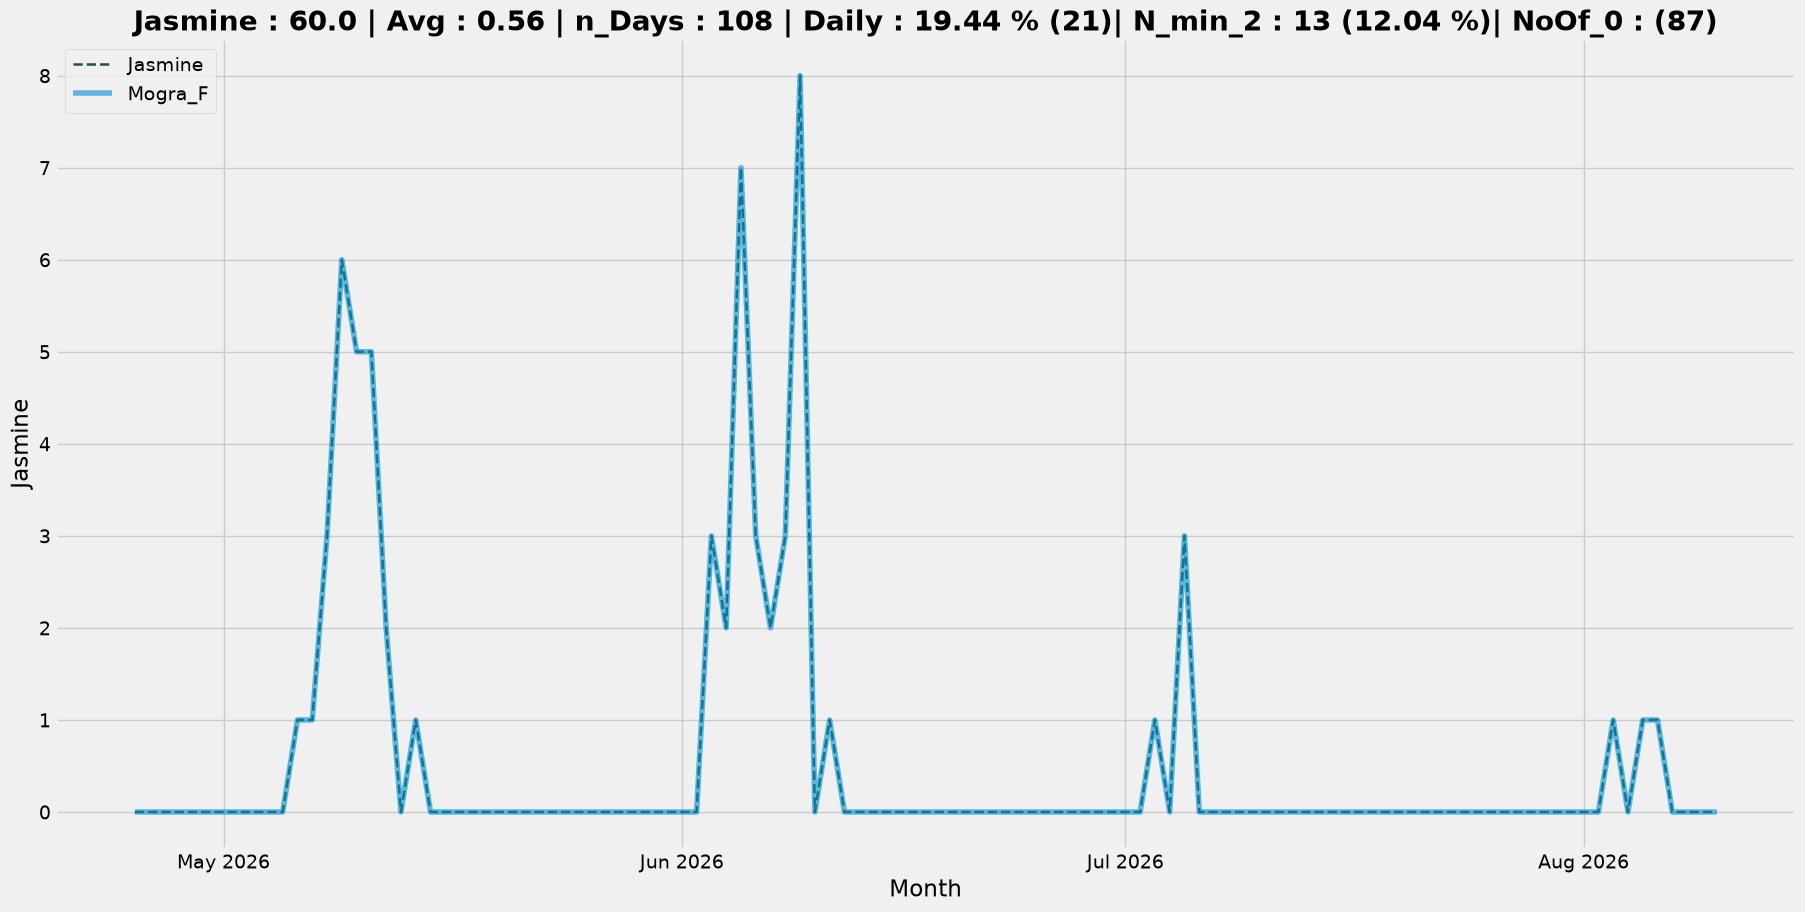

In [78]:
plot_by_Cat("Jasmine", show_total = False, show_cat = True, show_sub_cat = True, n_min = 2)

In [72]:
main_df.tail()

,Date,Total,Hibiscus_F,Kolkata_Pan_L,Mogai_Pan_L,Tulsi_Rama_L,Aloe_Vera_L,Tulsi_Sabja_L,Parijatak_L,Lemon_Grass_L,Tulsi_Kapoor_L,Tulsi_Krishna_L,Pudina_L,Brahmi_L,Nirgundi_L,Pippali_L,Adulsa_L,Mogra_F,Tulsi_Sabja_F,Neem_L,Tulsi_sabja_L,Rose_F,Fertiliser,Double_Tagar_F,Curry_L,Tulsi_Krishna_F,Jui_L,Sita_Ashoka_L,Hibiscus_L
103,2026-08-06,3.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
104,2026-08-07,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
105,2026-08-08,25.0,0.0,0.0,0.0,7.0,0.0,7.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,5.0,0.0
106,2026-08-09,47.0,0.0,0.0,0.0,7.0,0.0,7.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,30.0
107,2026-08-10,16.0,0.0,0.0,0.0,0.0,0.0,7.0,0.0,0.0,0.0,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0


# TODAY's HARVEST

In [73]:
for _, (row_name, row_value) in enumerate(zip(main_df.columns, main_df.iloc[-1].to_list())):
    # print(row_value, type(row_value))
    if row_name != "Date" and row_value > 0: 
        print(f"{row_name} : {row_value}")

Total : 16.0
Tulsi_Sabja_L : 7.0
Tulsi_Krishna_L : 7.0
Double_Tagar_F : 2.0
